# Real Interest Rates in Canada: Is Money Cheap or Tight After Inflation?

**Author:** John Khan

**Question.** A 2.25% policy rate sounds low next to the 5% of 2023. But what matters for borrowers and savers is the rate after inflation. How has Canada's real policy rate moved since 2009, how long was it below zero, and where does it sit now?

**Definition.** The real rate here is the simple backward looking (ex post) version: nominal rate minus inflation over the past 12 months. I show it against headline CPI and against core inflation (the average of the Bank of Canada's CPI trim and CPI median).

**Data (live from the Bank of Canada Valet API, https://www.bankofcanada.ca/valet/docs):**

| Series ID | What it is | Frequency |
|---|---|---|
| `V39079` | Target for the overnight rate (policy rate), from April 2009 | Business daily |
| `V41690973` | Total CPI, not seasonally adjusted, 2002 = 100 (Statistics Canada, table 18-10-0004-01) | Monthly |
| `CPI_TRIM`, `CPI_MEDIAN` | Bank of Canada core inflation measures, year over year % | Monthly |
| `BD.CDN.5YR.DQ.YLD` | Government of Canada 5 year benchmark bond yield | Business daily |

If the API is down, the notebook reads the snapshot it saved in `data/`.

In [1]:
import io, os, json
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

BLUE = "#011F5B"
RED = "#990000"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#444444",
    "axes.grid": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "legend.frameon": False,
})
TITLE_FONT = {"family": "serif", "weight": "bold", "size": 15}

VALET = "https://www.bankofcanada.ca/valet/observations/{ids}/json"
SNAPSHOT_DIR = "data"

def valet(series, start=None, snapshot=None):
    """Pull one or more Bank of Canada Valet series into a DataFrame.
    If the live pull fails, fall back to a CSV snapshot saved next to the notebook
    (on Kaggle, upload the snapshot CSV as a dataset and point SNAPSHOT_DIR at it)."""
    ids = ",".join(series)
    params = {"start_date": start} if start else {}
    try:
        r = requests.get(VALET.format(ids=ids), params=params, timeout=60)
        r.raise_for_status()
        obs = r.json()["observations"]
        rows = []
        for o in obs:
            row = {"date": o["d"]}
            for s in series:
                v = o.get(s, {}).get("v")
                row[s] = float(v) if v not in (None, "") else np.nan
            rows.append(row)
        df = pd.DataFrame(rows)
        df["date"] = pd.to_datetime(df["date"])
        df = df.set_index("date").sort_index()
        if snapshot:
            os.makedirs(SNAPSHOT_DIR, exist_ok=True)
            df.to_csv(os.path.join(SNAPSHOT_DIR, snapshot))
        print(f"Live pull OK: {ids} ({len(df)} rows, {df.index.min().date()} to {df.index.max().date()})")
        return df
    except Exception as e:
        path = os.path.join(SNAPSHOT_DIR, snapshot or "missing.csv")
        print(f"Live pull failed ({e}). Reading snapshot {path}")
        return pd.read_csv(path, index_col="date", parse_dates=True)

def style(ax, title, ylabel=None):
    ax.set_title(title, fontdict=TITLE_FONT, loc="left", color=BLUE)
    if ylabel:
        ax.set_ylabel(ylabel)
    return ax

def save(fig, name):
    os.makedirs("charts", exist_ok=True)
    fig.tight_layout()
    fig.savefig(os.path.join("charts", name), dpi=150, bbox_inches="tight")
    plt.show()


## 1. Pull and line up the data

In [2]:
rates = valet(["V39079", "BD.CDN.5YR.DQ.YLD"], start="2009-04-01", snapshot="daily_policy_bond.csv")
cpi = valet(["V41690973", "CPI_TRIM", "CPI_MEDIAN"], start="2008-01-01", snapshot="monthly_cpi.csv")
rates = rates.rename(columns={"V39079": "policy", "BD.CDN.5YR.DQ.YLD": "bond5"})
cpi = cpi.rename(columns={"V41690973": "cpi_index", "CPI_TRIM": "trim", "CPI_MEDIAN": "median"})

cpi["headline"] = cpi["cpi_index"].pct_change(12, fill_method=None) * 100
cpi["core"] = cpi[["trim", "median"]].mean(axis=1)

m = pd.concat([rates.resample("MS").mean(), cpi[["headline", "core"]]], axis=1, sort=True)
m = m.loc["2009-05-01":].dropna(subset=["policy", "headline"])
m["real_policy"] = m["policy"] - m["headline"]
m["real_policy_core"] = m["policy"] - m["core"]
m["real_bond5"] = m["bond5"] - m["headline"]
print("Months:", len(m), "|", m.index.min().strftime("%B %Y"), "to", m.index.max().strftime("%B %Y"))
m.tail(6).round(2)

Live pull OK: V39079,BD.CDN.5YR.DQ.YLD (4564 rows, 2009-04-01 to 2026-10-15)
Live pull OK: V41690973,CPI_TRIM,CPI_MEDIAN (224 rows, 2008-01-01 to 2026-08-01)
Months: 208 | May 2009 to August 2026


,policy,bond5,headline,core,real_policy,real_policy_core,real_bond5
date,,,,,,,
2026-03-01,2.25,3.03,2.39,2.25,-0.14,0.00,0.64
2026-04-01,2.25,3.10,2.82,2.05,-0.57,0.20,0.28
2026-05-01,2.25,3.19,3.23,2.05,-0.98,0.20,-0.03
2026-06-01,2.25,3.06,2.80,1.90,-0.55,0.35,0.27
2026-07-01,2.25,3.16,3.03,1.95,-0.78,0.30,0.13
2026-08-01,2.25,3.28,3.03,1.95,-0.78,0.30,0.25


In [3]:
# sanity check: the headline rate computed from the index should match Statistics Canada's published figure
print(cpi[["cpi_index", "headline"]].dropna().tail(3).round(2))

            cpi_index  headline
date                           
2026-06-01      169.0      2.80
2026-07-01      169.9      3.03
2026-08-01      169.8      3.03


## 2. Nominal rate against inflation

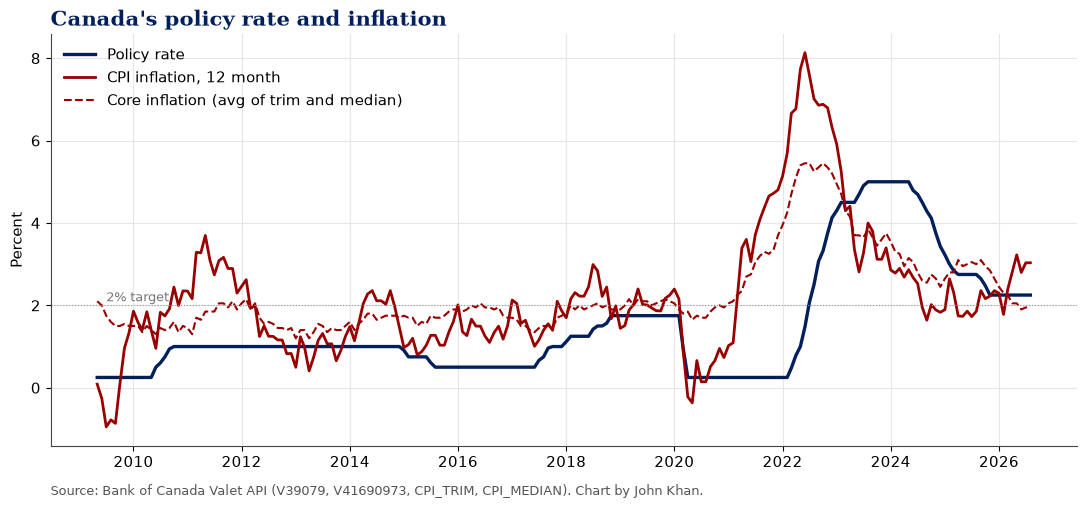

In [4]:
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.plot(m.index, m["policy"], color=BLUE, lw=2.4, label="Policy rate")
ax.plot(m.index, m["headline"], color=RED, lw=2, label="CPI inflation, 12 month")
ax.plot(m.index, m["core"], color=RED, lw=1.5, ls="--", label="Core inflation (avg of trim and median)")
ax.axhline(2, color="#999999", lw=0.8, ls=":")
ax.text(m.index[2], 2.1, "2% target", color="#777777", fontsize=9)
style(ax, "Canada's policy rate and inflation", "Percent")
ax.legend(loc="upper left")
ax.text(0, -0.12, "Source: Bank of Canada Valet API (V39079, V41690973, CPI_TRIM, CPI_MEDIAN). Chart by John Khan.", transform=ax.transAxes, fontsize=9, color="#555555")
save(fig, "01_policy_vs_inflation.png")

## 3. The real policy rate

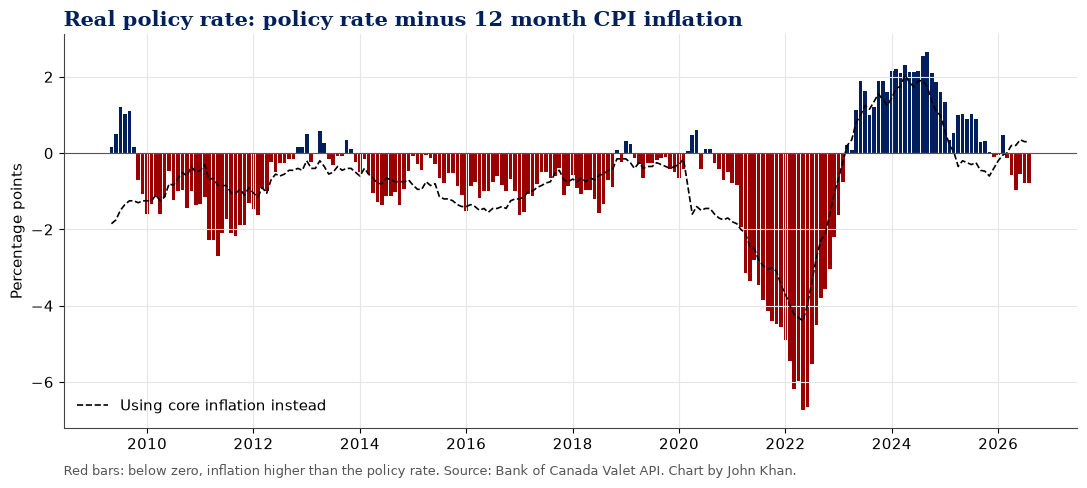

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
rp = m["real_policy"]
ax.bar(rp.index, rp, width=25, color=[RED if v < 0 else BLUE for v in rp])
ax.plot(m.index, m["real_policy_core"], color="black", lw=1.2, ls="--", label="Using core inflation instead")
ax.axhline(0, color="#555555", lw=0.8)
style(ax, "Real policy rate: policy rate minus 12 month CPI inflation", "Percentage points")
ax.legend(loc="lower left")
ax.text(0, -0.12, "Red bars: below zero, inflation higher than the policy rate. Source: Bank of Canada Valet API. Chart by John Khan.", transform=ax.transAxes, fontsize=9, color="#555555")
save(fig, "02_real_policy_rate.png")

In [6]:
def runs(mask):
    """Return (start, end, length) of each run of True values."""
    out, start, prev = [], None, None
    for t, v in mask.items():
        if v and start is None: start = t
        if not v and start is not None:
            out.append((start, prev, len(mask.loc[start:prev]))); start = None
        prev = t
    if start is not None: out.append((start, prev, len(mask.loc[start:prev])))
    return out

neg = m["real_policy"] < 0
r_runs = sorted(runs(neg), key=lambda x: -x[2])
f = lambda t: t.strftime("%b %Y")
print(f"Months with a negative real policy rate: {int(neg.sum())} of {len(m)} ({neg.mean() * 100:.0f}%)")
print(f"Longest run: {f(r_runs[0][0])} to {f(r_runs[0][1])}, {r_runs[0][2]} months")
cur = runs(neg)[-1]
if cur[1] == m.index[-1]:
    print(f"Current run: negative since {f(cur[0])}, {cur[2]} months")
lo = m["real_policy"].idxmin()
print(f"Most negative: {m.loc[lo, 'real_policy']:.2f} pts in {f(lo)} (policy {m.loc[lo, 'policy']:.2f}%, CPI {m.loc[lo, 'headline']:.1f}%)")
hi = m["real_policy"].idxmax()
print(f"Most positive: {m.loc[hi, 'real_policy']:.2f} pts in {f(hi)} (policy {m.loc[hi, 'policy']:.2f}%, CPI {m.loc[hi, 'headline']:.1f}%)")
last = m.index[-1]
print(f"Latest, {f(last)}: policy {m.loc[last, 'policy']:.2f}%, CPI {m.loc[last, 'headline']:.1f}%, core {m.loc[last, 'core']:.2f}%, real {m.loc[last, 'real_policy']:+.2f} pts, real on core {m.loc[last, 'real_policy_core']:+.2f} pts")
pos = m.loc["2023":, "real_policy"]
print(f"Since 2023: average real policy rate {pos.mean():+.2f} pts; months above +2: {int((pos > 2).sum())}")
for a0, a1, n in runs(neg):
    if a0 <= lo <= a1:
        print(f"The inflation era run: negative from {f(a0)} to {f(a1)}, {n} months")
avg_2010s = m.loc["2010":"2019", "real_policy"].mean()
print(f"Average real policy rate, 2010 to 2019: {avg_2010s:+.2f} pts")

Months with a negative real policy rate: 152 of 208 (73%)
Longest run: Dec 2013 to Oct 2018, 59 months
Current run: negative since Mar 2026, 6 months
Most negative: -6.73 pts in May 2022 (policy 1.00%, CPI 7.7%)
Most positive: 2.65 pts in Sep 2024 (policy 4.29%, CPI 1.6%)
Latest, Aug 2026: policy 2.25%, CPI 3.0%, core 1.95%, real -0.78 pts, real on core +0.30 pts
Since 2023: average real policy rate +0.92 pts; months above +2: 10
The inflation era run: negative from Sep 2020 to Feb 2023, 30 months
Average real policy rate, 2010 to 2019: -0.78 pts


## 4. What about the rate that sets fixed mortgages?

Five year fixed mortgages price off the five year bond, so the real five year yield is closer to what a fixed rate borrower feels. I subtract the same 12 month CPI inflation.

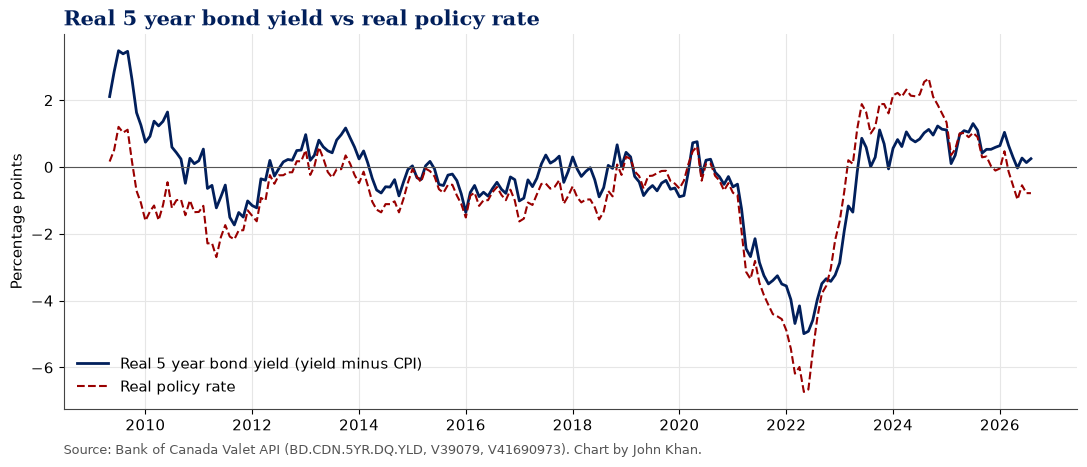

Real 5 year yield, latest Aug 2026: +0.25 pts; average 2010 to 2019: -0.17; low -4.99 in May 2022
Gap, real 5 year minus real policy, latest: +1.03 pts


In [7]:
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(m.index, m["real_bond5"], color=BLUE, lw=2, label="Real 5 year bond yield (yield minus CPI)")
ax.plot(m.index, m["real_policy"], color=RED, lw=1.5, ls="--", label="Real policy rate")
ax.axhline(0, color="#555555", lw=0.8)
style(ax, "Real 5 year bond yield vs real policy rate", "Percentage points")
ax.legend(loc="lower left")
ax.text(0, -0.12, "Source: Bank of Canada Valet API (BD.CDN.5YR.DQ.YLD, V39079, V41690973). Chart by John Khan.", transform=ax.transAxes, fontsize=9, color="#555555")
save(fig, "03_real_bond_vs_real_policy.png")
rb = m["real_bond5"].dropna()
print(f"Real 5 year yield, latest {f(rb.index[-1])}: {rb.iloc[-1]:+.2f} pts; average 2010 to 2019: {rb.loc['2010':'2019'].mean():+.2f}; low {rb.min():+.2f} in {f(rb.idxmin())}")
print(f"Gap, real 5 year minus real policy, latest: {(m['real_bond5'] - m['real_policy']).iloc[-1]:+.2f} pts")

## 5. Conclusion

*Figures below are from the run on October 18, 2026, with CPI through August 2026.*

**1. Below zero is normal for Canada's real policy rate.** In 152 of the 208 months since May 2009 (73%), the policy rate was lower than 12 month CPI inflation. The longest stretch ran 59 months, from December 2013 to October 2018. Across 2010 to 2019 the real policy rate averaged minus 0.78 points.

**2. 2022 was the extreme.** The real policy rate stayed negative for 30 months, from September 2020 to February 2023. It bottomed at minus 6.73 points in May 2022, when the policy rate averaged 1.00% and CPI inflation was 7.7%.

**3. Then policy was genuinely tight for a while.** From 2023 on, the real policy rate averaged plus 0.92 points, and it sat above plus 2 points in 10 months. The peak was plus 2.65 points in September 2024 (policy 4.29%, CPI 1.6%).

**4. Now it depends on which inflation you use.** In August 2026 the policy rate was 2.25% and headline CPI inflation was 3.0%, so the real rate on headline CPI is minus 0.78 points and has been negative for six months, since March 2026. Against core inflation (1.95%), the real rate is plus 0.30 points. On headline, the real rate is right at its 2010 to 2019 average. On core, it is slightly positive.

**5. Fixed rate borrowers face a higher real rate than the headline suggests.** The real five year bond yield was plus 0.25 points in August 2026, about 1.03 points above the real policy rate, and above its 2010 to 2019 average of minus 0.17 points.

**What this means.** With headline inflation above the policy rate, money is not tight in real terms on the measure most people see. Core inflation tells a different story, and so does the five year bond, which is the rate that matters for anyone renewing into a fixed mortgage.


## Notes and limits

* This is the backward looking real rate. Central banks think in terms of expected inflation, which can differ from the last 12 months.
* Monthly averages of the daily rates are matched to the CPI month. CPI is published with about a three week lag, so the latest month here trails the latest rate data.
* Headline CPI swings with gasoline and other volatile prices. The core version is shown for that reason.
* Every figure is printed by the code from the data pulled on the run date.

*Data: Bank of Canada, Valet API, https://www.bankofcanada.ca/valet/docs (terms: https://www.bankofcanada.ca/terms/). CPI: Statistics Canada, table 18-10-0004-01, https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=1810000401, via the Bank of Canada.*